# #33 round 2: token fertility on the cleaned corpora

Round 1 (`33-nl-token-fertility.ipynb`, PR #39) used 200 Gita words. Here we use the SLP1 text from #34 (two corpora, kept separate)
and a much larger sample, with SLP1 as the main encoding. Same tokenizers and measures as round 1.

In [22]:
import csv
import random
import re
import string
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from indic_transliteration import sanscript
from transformers import AutoTokenizer

from sandhi_probe import paths

# SLP1  as main encoding
ENCODINGS = {
    "SLP1": sanscript.SLP1,
    "Devanagari": sanscript.DEVANAGARI,
    "IAST": sanscript.IAST,
    "HK": sanscript.HK,
}
TOKENIZERS = {
    "gpt2": "gpt2",
    "qwen2.5": "Qwen/Qwen2.5-0.5B",
    "byt5": "google/byt5-small",
}
N_WORDS = 2000
SEED = 0

## Words

Input is the SLP1 text Eric handed over for #34 (`samples_slp1.zip`, unzipped into the gitignored `data/raw/slp1_samples/`):
- **DCS**: Rigveda, `text` column of the tab-separated file. Short, space-separated words.
- **UoH**: the Vinodini prose text. Long fused compounds.

The files are not fully clean for counting tokens, so each word is cleaned first. All of this is ours, not Eric's:
- remove the BOM and zero-width non-joiners (U+200C), which sit inside some UoH words;
- trim punctuation from word edges, keeping the apostrophe (the avagraha in SLP1);
- keep only words made of ASCII letters and apostrophes. This drops digits, lone hyphens, hyphenated line-end fragments and the
  DCS words containing `ṁ` (an IAST symbol the converter left behind, not valid SLP1).

We then take up to `N_WORDS` distinct words per corpus at random (fixed seed).

In [23]:
SLP1_DIR = paths.RAW_DIR / "slp1_samples"
EDGE_PUNCT = ',;:."?=+~()-'


def clean_words(text: str) -> list[str]:
    out = []
    for w in text.replace("\ufeff", "").replace("\u200c", "").split():
        w = w.strip(EDGE_PUNCT)
        if re.fullmatch(r"[A-Za-z']*[A-Za-z][A-Za-z']*", w):
            out.append(w)
    return out


with open(SLP1_DIR / "pada-and-analysis-slp1.dat", encoding="utf-8", newline="") as f:
    dcs_text = " ".join(
        r["text"] for r in csv.DictReader(f, delimiter="\t", quoting=csv.QUOTE_NONE)
    )
uoh_text = (SLP1_DIR / "vinodini_p-slp1.txt").read_text(encoding="utf-8-sig")

rng = random.Random(SEED)
corpora = {}
for name, text in {"DCS": dcs_text, "UoH": uoh_text}.items():
    raw = text.split()
    kept = clean_words(text)
    types = sorted(set(kept))
    corpora[name] = rng.sample(types, min(N_WORDS, len(types)))
    print(
        f"{name}: {len(raw)} raw tokens, {len(kept)} kept ({len(raw) - len(kept)} dropped), "
        f"{len(types)} distinct, sampled {len(corpora[name])}"
    )

DCS: 164753 raw tokens, 162900 kept (1853 dropped), 28665 distinct, sampled 2000
UoH: 2973 raw tokens, 2861 kept (112 dropped), 2166 distinct, sampled 2000


### Illegal characters

Words that get rejected by the above filter, grouped by character

In [24]:
TOP_N = 5
LEGAL = set(string.ascii_letters + "'")


def shorten(w: str, width: int = 40) -> str:
    return w if len(w) <= width else w[: width - 3] + "..."


def rejected_words(text: str) -> Counter:
    """Occurrences of each word that `clean_words` would reject."""
    rejected = Counter()
    for w in text.replace("\ufeff", "").replace("\u200c", "").split():
        w = w.strip(EDGE_PUNCT)
        if w and not re.fullmatch(r"[A-Za-z']*[A-Za-z][A-Za-z']*", w):
            rejected[w] += 1
    return rejected


rows = []
for corpus, text in {"DCS": dcs_text, "UoH": uoh_text}.items():
    by_char: dict[str, Counter] = {}
    for w, n in rejected_words(text).items():
        for ch in set(w) - LEGAL:
            by_char.setdefault(ch, Counter())[w] += n
    for ch, words_with_ch in by_char.items():
        rows.append(
            {
                "corpus": corpus,
                "char": ch,
                "name": unicodedata.name(ch, "?"),
                "tokens": sum(words_with_ch.values()),
                "distinct words": len(words_with_ch),
                "examples": ", ".join(shorten(w) for w, _ in words_with_ch.most_common(TOP_N)),
            }
        )
illegal = pd.DataFrame(rows).sort_values(["corpus", "tokens"], ascending=[True, False])
illegal.reset_index(drop=True)

,corpus,char,name,tokens,distinct words,examples
0,DCS,ṁ,LATIN SMALL LETTER M WITH DOT ABOVE,1843,748,"aṁhasaH, rajAṁsi, aṁhaH, tamAṁsi, Saṁsam"
1,DCS,*,ASTERISK,7,7,"rodasI*, mimikzuH*, karizyAH*, vrajam*, vasavA..."
2,DCS,0,DIGIT ZERO,3,2,"cAkk0pre, cIkk0pAti"
3,UoH,-,HYPHEN-MINUS,5,5,"vinigamanAvirahAdAha-asmeti, pravfttAvupAyamAh..."
4,UoH,"""",QUOTATION MARK,2,2,"lakzaRAdi""ti, tvayI""tyAdAvasmacCabdenarzeryuzm..."
5,UoH,+,PLUS SIGN,2,2,"SAbdaboDe+api, yat+vA+avacCedyatvasambanDAvacC..."
6,UoH,1,DIGIT ONE,1,1,1
7,UoH,2,DIGIT TWO,1,1,2
8,UoH,3,DIGIT THREE,1,1,3
9,UoH,4,DIGIT FOUR,1,1,4


## Transliterate

Transliterate SLP1 into the other encodings
As a check, also convert Devanagari back to SLP1 and count exact matches

In [25]:
forms = {
    corpus: pd.DataFrame(
        {
            enc: [
                w if enc == "SLP1" else sanscript.transliterate(w, sanscript.SLP1, scheme)
                for w in words
            ]
            for enc, scheme in ENCODINGS.items()
        }
    )
    for corpus, words in corpora.items()
}
for corpus, df in forms.items():
    back = [
        sanscript.transliterate(d, sanscript.DEVANAGARI, sanscript.SLP1) for d in df["Devanagari"]
    ]
    ok = sum(b == w for b, w in zip(back, df["SLP1"], strict=True))
    print(f"{corpus}: SLP1 -> Devanagari -> SLP1 exact for {ok}/{len(df)} words")
forms["UoH"].head()

DCS: SLP1 -> Devanagari -> SLP1 exact for 2000/2000 words
UoH: SLP1 -> Devanagari -> SLP1 exact for 2000/2000 words


,SLP1,Devanagari,IAST,HK
0,uddeSyatA'vacCedake'BedAnvayisvArTakakiMpadasya,उद्देश्यताऽवच्छेदकेऽभेदान्वयिस्वार्थककिंपदस्य,uddeśyatā'vacchedake'bhedānvayisvārthakakiṃpad...,uddezyatA'vacchedake'bhedAnvayisvArthakakiMpad...
1,tAdfSavAdarUpameva,तादृशवादरूपमेव,tādṛśavādarūpameva,tAdRzavAdarUpameva
2,izwaH,इष्टः,iṣṭaḥ,iSTaH
3,GawAdyarTavizayatAyAM,घटाद्यर्थविषयतायां,ghaṭādyarthaviṣayatāyāṃ,ghaTAdyarthaviSayatAyAM
4,zazWItatpuruze,षष्ठीतत्पुरुषे,ṣaṣṭhītatpuruṣe,SaSThItatpuruSe


## Tokenize

Tokenize + measure:
- tokens/word
- tokens/character
- "partial" tokens (tokens that are only part of a UTF-8 character)

In [26]:
tokenizers = {name: AutoTokenizer.from_pretrained(path) for name, path in TOKENIZERS.items()}

rows = []
for corpus, df in forms.items():
    for t, tok in tokenizers.items():
        for enc in ENCODINGS:
            for w in df[enc]:
                ids = tok(w, add_special_tokens=False).input_ids
                decoded = [tok.decode([i]) for i in ids]
                # ByT5 decodes a lone partial byte to "", the others to "\ufffd"
                partial = sum("\ufffd" in d or d == "" for d in decoded)
                rows.append(
                    {
                        "corpus": corpus,
                        "tokenizer": t,
                        "encoding": enc,
                        "chars": len(w),
                        "tokens": len(ids),
                        "partial": partial,
                    }
                )
counts = pd.DataFrame(rows)

by = counts.groupby(["corpus", "tokenizer", "encoding"])
mean_tokens = by.tokens.mean().unstack()[list(ENCODINGS)]
mean_tokens.round(2)

encoding           SLP1  Devanagari   IAST     HK
corpus tokenizer                                 
DCS    byt5        7.48       21.51   9.95   7.80
       gpt2        4.08       13.85   5.47   4.15
       qwen2.5     3.90        7.43   4.52   3.99
UoH    byt5       19.99       55.71  25.15  20.88
       gpt2       10.49       35.60  13.37  10.61
       qwen2.5    10.03       18.71  11.62  10.18

## Plot: mean tokens per word

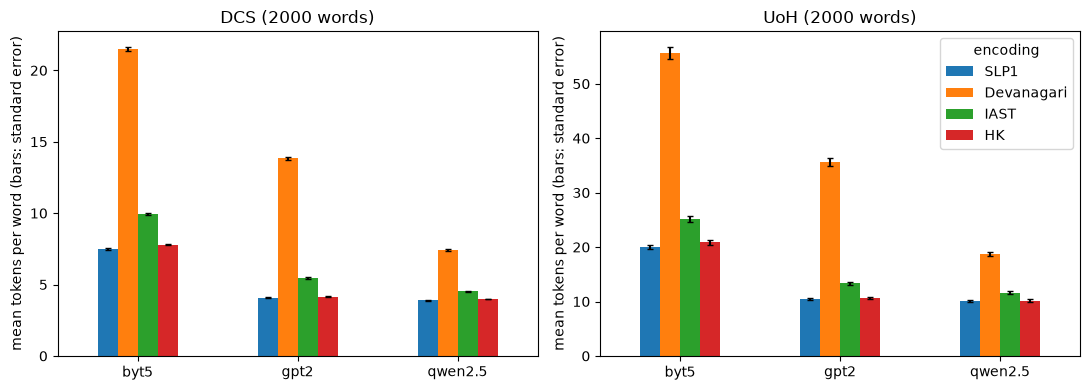

In [27]:
sem = by.tokens.sem().unstack()[list(ENCODINGS)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, corpus in zip(axes, forms, strict=True):
    mean_tokens.loc[corpus].plot.bar(yerr=sem.loc[corpus], rot=0, ax=ax, legend=False, capsize=2)
    ax.set_title(f"{corpus} ({len(corpora[corpus])} words)")
    ax.set_xlabel("")
    ax.set_ylabel("mean tokens per word (bars: standard error)")
axes[1].legend(title="encoding")
plt.tight_layout()
plt.savefig(paths.INTERIM_DIR / "33-round2-token-fertility.png", dpi=200)  # gitignored
plt.show()

## Supporting table: tokens per character and partial characters

`tokens_per_char`: (# tokens / word length in characters)
Ex: near 1 would mean cutting every character on average

`partial_char_share` is the share of tokens that are only part of a UTF-8 character

Observations
- byt5 is 1.00 for SLP1, HK and 3.00 for Devanagari (every byte becomes one token)
  - IAST has Latin characters with accents, can be 2-3 bytes each

In [28]:
support = counts.groupby(["corpus", "tokenizer", "encoding"])[["chars", "tokens", "partial"]].sum()
support["tokens_per_char"] = support.tokens / support.chars
support["partial_char_share"] = support.partial / support.tokens
support[["tokens_per_char", "partial_char_share"]].round(2).unstack().reindex(
    columns=list(ENCODINGS), level="encoding"
)

tokens_per_char                        partial_char_share  \
encoding                    SLP1 Devanagari  IAST    HK               SLP1   
corpus tokenizer                                                             
DCS    byt5                 1.00       3.00  1.28  1.00                0.0   
       gpt2                 0.54       1.93  0.70  0.53                0.0   
       qwen2.5              0.52       1.04  0.58  0.51                0.0   
UoH    byt5                 1.00       3.00  1.20  1.00                0.0   
       gpt2                 0.52       1.92  0.64  0.51                0.0   
       qwen2.5              0.50       1.01  0.56  0.49                0.0   

                                        
encoding         Devanagari  IAST   HK  
corpus tokenizer                        
DCS    byt5            1.00  0.36  0.0  
       gpt2            0.96  0.29  0.0  
       qwen2.5         0.49  0.00  0.0  
UoH    byt5            1.00  0.30  0.0  
       gpt2            0.96  0.20  0.0  
       qwen2.5         0.61  0.00  0.0

## Round 1 vs round 2

Round 1 (200 Bhagavad Gita words):

| tokenizer | Devanagari | HK | IAST | SLP1 |
|---|---|---|---|---|
| byt5 | 24.4 | 9.1 | 11.3 | 8.7 |
| gpt2 | 15.7 | 4.8 | 6.1 | 4.7 |
| qwen2.5 | 8.4 | 4.6 | 5.1 | 4.6 |

Round 2 (2,000 words per corpus, SLP1 text from #34):

| corpus | tokenizer | SLP1 | Devanagari | IAST | HK |
|---|---|---|---|---|---|
| DCS | byt5 | 7.5 | 21.5 | 9.9 | 7.8 |
| DCS | gpt2 | 4.1 | 13.9 | 5.5 | 4.2 |
| DCS | qwen2.5 | 3.9 | 7.4 | 4.5 | 4.0 |
| UoH | byt5 | 20.0 | 55.7 | 25.2 | 20.9 |
| UoH | gpt2 | 10.5 | 35.6 | 13.4 | 10.6 |
| UoH | qwen2.5 | 10.0 | 18.7 | 11.6 | 10.2 |

Summary:
- SLP1 and HK never cut inside a character, being ASCII
- Devanagari remains expensive
- IAST is in between, having latin characters with accents

**Similarities as R1**
- Devanagari costs 1.9-3.4x as many tokens as SLP1 on every tokenizer and both corpora (round 1: 1.8-3.3x).
- In SLP1 and HK, GPT-2 and Qwen are within about 5% of each other, while in Devanagari Qwen needs roughly half as many tokens as GPT-2.
- Most of GPT-2's Devanagari tokens (96%) are fragments of a character; for Qwen it is 49-61% (round 1: 51%). ByT5 is exactly 1 token per character in SLP1 and 3 in Devanagari.

**Differences from R1**
- Absolute counts depend a lot on the corpus: UoH words are long fused compounds (about 20 SLP1 characters) and cost roughly 2.5x as many tokens as DCS words (about 8 characters).
- SLP1 and HK are no longer interchangeable: SLP1 is slightly but consistently cheaper (about 4% fewer tokens on ByT5, 1-2% on GPT-2 and Qwen), because HK writes some single sounds as two letters. We did not test whether this exceeds sampling noise (the plot has standard-error bars).
- The sample is 10x larger and covers two very different corpora, so the round 1 pattern is not an artefact of one chapter of the Gita.

**Notes/Caveats**
- I removed the words containing `ṁ` (about 1% of DCS tokens) and cleaned UoH ourselves; see the Words section. Results may shift slightly once #34's files are fixed.
- SLP1 -> Devanagari -> SLP1 round-trips exactly for all sampled words, so the Devanagari, IAST and HK columns are trustworthy for this sample.
- Fertility says nothing yet about whether cuts fall on sandhi boundaries.